## Лабораторная работа №1 | Вариант 6

Выполнил: Ергизов Алексей Радикович, М8О-311БВ-24

### 1. Numpy

In [2]:
import numpy as np

1. Создайте единичную матрицу размером 3х3

In [3]:
np.eye(3)

array([[1., 0., 0.],
       [0., 1., 0.],
       [0., 0., 1.]])

2. Создайте матрицу 5х5 со значениями 1, 2, 3, 4 ниже диагонали

In [4]:
np.diag([1, 2, 3, 4], k=-1)

array([[0, 0, 0, 0, 0],
       [1, 0, 0, 0, 0],
       [0, 2, 0, 0, 0],
       [0, 0, 3, 0, 0],
       [0, 0, 0, 4, 0]])

3. Какой выход будет у данного скрипта

```python
# Author: Jake VanderPlas

print(sum(range(5),-1))
from numpy import *
print(sum(range(5),-1))
```

In [5]:
# встроенный sum берет -1 как start (0+1+2+3+4 - 1 = 9),
# а numpy.sum воспринимает -1 как ось axis=-1 (сумма элементов = 10)
print(sum(range(5), -1))
from numpy import *
print(sum(range(5), -1))

9
10


4. Как найти самое часто встречаемое значение между двумя массивами? 

In [6]:
a = np.array([1, 2, 3, 4, 2, 5])
b = np.array([2, 5, 2, 6, 7, 2])

combined = np.concatenate([a, b])
vals, counts = np.unique(combined, return_counts=True)
most_frequent = vals[np.argmax(counts)]

print("Самое частое значение:", most_frequent)

Самое частое значение: 2


5. Как игнорировать все warnings в numpy(не нужно так делать, но покажи)?

In [7]:
# игнорирование всех warnings в numpy
np.seterr(all='ignore')

# проверка деления на ноль без warning
res = np.ones(3) / 0
print(res)

[inf inf inf]


6. Реализуем функцию-генератор, которая генерирует 10 целых чисел и используем ее для построения массива

In [8]:
def gen():
    for x in range(10):
        yield x

arr = np.fromiter(gen(), dtype=int)
print(arr)

[0 1 2 3 4 5 6 7 8 9]


7. Создайте массив случайных чисел размером 10 и отсортируйте его

In [11]:
arr = np.random.rand(10)
sorted_arr = np.sort(arr)
print("Исходный:", arr)
print("Отсортированный:", sorted_arr)

Исходный: [0.40362245 0.61483291 0.9459899  0.59555745 0.21076047 0.40294205
 0.4460725  0.45860718 0.54739208 0.1644915 ]
Отсортированный: [0.1644915  0.21076047 0.40294205 0.40362245 0.4460725  0.45860718
 0.54739208 0.59555745 0.61483291 0.9459899 ]


8. Создайте случайную матрицу 10х2 которая представляет собой декартовые координаты и преобразуйте их в полярные

In [12]:
coords = np.random.rand(10, 2)
x, y = coords[:, 0], coords[:, 1]

r = np.hypot(x, y)
theta = np.arctan2(y, x)

polar = np.column_stack((r, theta))
print("Полярные координаты (r, theta):\n", polar)

Полярные координаты (r, theta):
 [[1.05861708 0.47209559]
 [0.59963691 1.36015384]
 [0.98581404 0.09885929]
 [0.9905158  0.78348892]
 [0.86839754 0.61445552]
 [0.64672687 0.50650322]
 [0.79809678 0.55093832]
 [0.27812972 0.36520367]
 [0.85004664 0.15033592]
 [0.89893558 0.02821239]]


9. Создайте структурированный массив который будет описывать пиксель(координату x, y и цвет r,g,b)

In [13]:
pixel_dtype = np.dtype([
    ('x', int),
    ('y', int),
    ('color', [('r', np.uint8), ('g', np.uint8), ('b', np.uint8)])
])

pixels = np.zeros(5, dtype=pixel_dtype)
pixels['x'] = [10, 20, 30, 40, 50]
pixels['y'] = [5, 15, 25, 35, 45]
pixels['color']['r'] = 255
pixels['color']['g'] = 128
pixels['color']['b'] = 0

print(pixels)

[(10,  5, (255, 128, 0)) (20, 15, (255, 128, 0)) (30, 25, (255, 128, 0))
 (40, 35, (255, 128, 0)) (50, 45, (255, 128, 0))]


10. Как конвертировать тип массив от float32 в int32 in place?

In [14]:
arr = np.array([1.2, 3.8, 5.5, 7.1], dtype=np.float32)
print("До:", arr, arr.dtype)

# через view и запись в тот же буфер памяти
arr_int = arr.view(np.int32)
arr_int[:] = arr

print("После:", arr_int, arr_int.dtype)

До: [1.2 3.8 5.5 7.1] float32
После: [1 3 5 7] int32


### 2. Pandas

Найдите ответы на вопросы или выполните действия с предложенным датасетом 

Набор данных описывает эффективность учеников в зависимости от некоторых факторов влияющих на обучение и окружение человека.

Файл: `student_perfomance.csv`

```
Hours_Studied - количество часов затраченное на обучение в неделю
Attendance - поцент посещенных занятий
Parental_Involvement - уровень участия родителей в обучении учащегося
Access_to_Resources - доступность ресурсов для обучения
Extracurricular_Activities - участие во внеклассных мероприятиях
Sleep_Hours - количество часов выделяемое на сон в день
Previous_Scores - оценка за первый экзамен
Motivation_Level - уровень мотивации
Internet_Access - доступ к интернету
Tutoring_Sessions - количество посещаемых репетиторских занятий в месяц.
Family_Income - доход семьи
Teacher_Quality - насколько качественно преподает учитель
School_Type - тип школы(частная, обычная)
Peer_Influence - влияние сверстников
Physical_Activity - физическая активность
Learning_Disabilities - наличие проблем с обучаемостью
Parental_Education_Level - уровень образования родителей
Distance_from_Home - дистанция от дома до школы
Gender - пол
Exam_Score - оценка на конечном экзамене
```

In [15]:
import pandas as pd

In [16]:
df = pd.read_csv('student_perfomance.csv')
df.head()

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


1. Посчитайте среднее кол-во часов уделяемое на сон студентами

In [17]:
mean_sleep = df['Sleep_Hours'].mean()
print(f"Среднее количество часов сна: {mean_sleep:.2f}")

Среднее количество часов сна: 7.03


2. Сколько процентов студентов посещают внеклассовые активности?

In [18]:
extra_pct = (df['Extracurricular_Activities'] == 'Yes').mean() * 100
print(f"Процент студентов с внеклассными активностями: {extra_pct:.2f}%")

Процент студентов с внеклассными активностями: 59.60%


3. Правда ли, что в среднем девушки сдают экзамены лучше, чем мужчины

In [21]:
gender_scores = df.groupby('Gender')['Exam_Score'].mean()
print(gender_scores)

if gender_scores['Female'] > gender_scores['Male']:
    print("Да, девушки сдают лучше, но разница мала.")
else:
    print("Нет, мужчины сдают лучше.")

Gender
Female    67.244898
Male      67.228894
Name: Exam_Score, dtype: float64
Да, девушки сдают лучше, но разница мала.


4. Выведите 25 и 75 перцентили времени сна студентов

In [22]:
q25, q75 = df['Sleep_Hours'].quantile([0.25, 0.75])
print(f"25-й перцентиль: {q25} ч.")
print(f"75-й перцентиль: {q75} ч.")

25-й перцентиль: 6.0 ч.
75-й перцентиль: 8.0 ч.


5. Правда ли, что те, кто спит больше(75 перцентиль и выше) сдает экзамен лучше, чем студенты с недосыпом(25 перцентиль и меньше)

In [23]:
score_sleep_high = df[df['Sleep_Hours'] >= q75]['Exam_Score'].mean()
score_sleep_low = df[df['Sleep_Hours'] <= q25]['Exam_Score'].mean()

print(f"Средний балл спящих >= {q75} ч: {score_sleep_high:.2f}")
print(f"Средний балл спящих <= {q25} ч: {score_sleep_low:.2f}")
print("Ответ: Нет, студенты с большим количеством сна не сдают экзамен лучше (баллы практически одинаковые).")

Средний балл спящих >= 8.0 ч: 67.19
Средний балл спящих <= 6.0 ч: 67.28
Ответ: Нет, студенты с большим количеством сна не сдают экзамен лучше (баллы практически одинаковые).


6. Влияет ли физическая активность на результаты экзамена?

In [24]:
print("Средний балл по уровню физической активности:")
print(df.groupby('Physical_Activity')['Exam_Score'].mean())

corr = df['Physical_Activity'].corr(df['Exam_Score'])
print(f"\nКорреляция: {corr:.4f}")
print("Ответ: Практически не влияет (корреляция около нуля, средний балл одинаков).")

Средний балл по уровню физической активности:
Physical_Activity
0    67.521739
1    66.969121
2    67.185003
3    67.196071
4    67.313016
5    67.603878
6    68.093750
Name: Exam_Score, dtype: float64

Корреляция: 0.0278
Ответ: Практически не влияет (корреляция около нуля, средний балл одинаков).


7. Правда ли, что слуденты, чьи родители имеют высшее образование(College || Postgraduate), сдают экзамены лучше, чем остальные?

In [ ]:
has_higher_ed = df['Parental_Education_Level'].isin(['College', 'Postgraduate'])

score_higher_ed = df[has_higher_ed]['Exam_Score'].mean()
score_other = df[~has_higher_ed]['Exam_Score'].mean()

print(f"Родители с высшим образованием: {score_higher_ed:.2f}")
print(f"Остальные: {score_other:.2f}")
print("Ответ: Да, студенты чьи родители имеют высшее образование, сдают экзамены лучше.")

Родители с высшим образованием: 67.58
Остальные: 66.90
Ответ: Да, студенты, чьи родители имеют высшее образование, сдают экзамены лучше.


8. Как влияет участие родителей на результаты экзаменов

In [27]:
inv_stats = df.groupby('Parental_Involvement')['Exam_Score'].agg(['mean', 'median', 'count'])
print(inv_stats)
print("\nВывод: Участие родителей положительно влияет на успеваемость - средний балл растет с ростом вовлеченности.")

                           mean  median  count
Parental_Involvement                          
High                  68.092767    68.0   1908
Low                   66.358265    66.0   1337
Medium                67.098156    67.0   3362

Вывод: Участие родителей положительно влияет на успеваемость - средний балл растет с ростом вовлеченности.


9. Правда ли, что в семьях с доходом больше среднего дети сдают экзамены лучше?

In [28]:
income_scores = df.groupby('Family_Income')['Exam_Score'].agg(['mean', 'median', 'count'])
print(income_scores)

overall_mean = df['Exam_Score'].mean()
high_mean = df[df['Family_Income'] == 'High']['Exam_Score'].mean()

print(f"\nСредний балл в группе High: {high_mean:.2f} (средний по всей выборке: {overall_mean:.2f})")
print("Ответ: Да, в семьях с доходом выше среднего дети сдают экзамены лучше.")

                    mean  median  count
Family_Income                          
High           67.842396    68.0   1269
Low            66.848428    67.0   2672
Medium         67.334959    67.0   2666

Средний балл в группе High: 67.84 (средний по всей выборке: 67.24)
Ответ: Да, в семьях с доходом выше среднего дети сдают экзамены лучше.


10. Посчитайте долю студентов сдавших экзамен на более чем 70 баллов в семьях с низким доходом и отсутствием доступа к интернету

In [29]:
subset = df[(df['Family_Income'] == 'Low') & (df['Internet_Access'] == 'No')]
share = (subset['Exam_Score'] > 70).mean()

print(f"Всего таких студентов: {len(subset)}")
print(f"Сдали на > 70 баллов: {(subset['Exam_Score'] > 70).sum()}")
print(f"Доля: {share:.4f} ({share * 100:.2f}%)")

Всего таких студентов: 211
Сдали на > 70 баллов: 17
Доля: 0.0806 (8.06%)


### 3. Визуализация

Используя библиотеки matplotlib/sns/plotly/pandas и набор данных представленный ранее визуализируйте

1. Правда ли, что количество часов затрачиваемых на сон распределено примерно нормально?

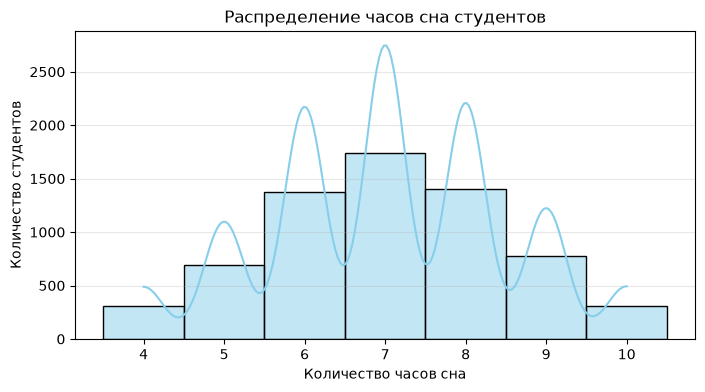

Асимметрия (skewness): -0.024
Вывод: Да, распределение симметрично и имеет колоколообразную форму с пиком около 7 часов, то есть распределено нормально.


In [31]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 4))
sns.histplot(df['Sleep_Hours'], kde=True, discrete=True, color='skyblue', edgecolor='black')
plt.title('Распределение часов сна студентов')
plt.xlabel('Количество часов сна')
plt.ylabel('Количество студентов')
plt.grid(axis='y', alpha=0.3)
plt.show()

print(f"Асимметрия (skewness): {df['Sleep_Hours'].skew():.3f}")
print("Вывод: Да, распределение симметрично и имеет колоколообразную форму с пиком около 7 часов, то есть распределено нормально.")

2. Постройте гистограмму распределения количества часов затрачиваемых на обучение среди мальчиков и девочек

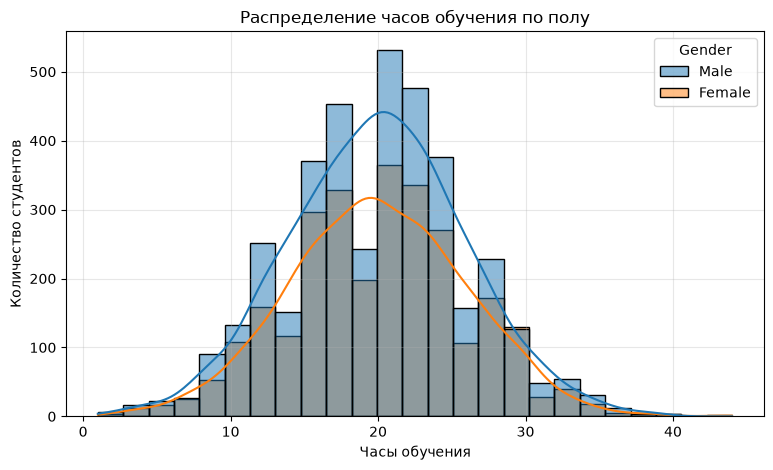

In [32]:
plt.figure(figsize=(9, 5))
sns.histplot(data=df, x='Hours_Studied', hue='Gender', kde=True, bins=25, alpha=0.5)
plt.title('Распределение часов обучения по полу')
plt.xlabel('Часы обучения')
plt.ylabel('Количество студентов')
plt.grid(alpha=0.3)
plt.show()

3. Как зависит результат конечного экзамена от результата первого экзамена

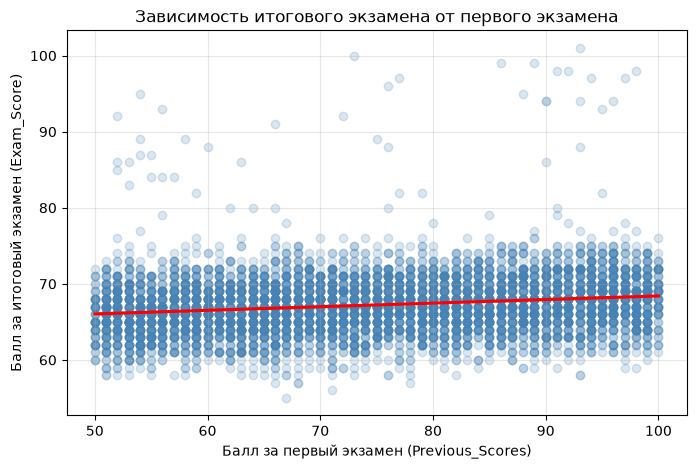

Коэффициент корреляции: 0.175
Вывод: Наблюдается прямая положительная зависимость - студенты с высоким баллом за первый экзамен лучше сдают итоговый.


In [34]:
plt.figure(figsize=(8, 5))
sns.regplot(data=df, x='Previous_Scores', y='Exam_Score',
            scatter_kws={'alpha': 0.2, 'color': 'steelblue'},
            line_kws={'color': 'red'})
plt.title('Зависимость итогового экзамена от первого экзамена')
plt.xlabel('Балл за первый экзамен (Previous_Scores)')
plt.ylabel('Балл за итоговый экзамен (Exam_Score)')
plt.grid(alpha=0.3)
plt.show()

print(f"Коэффициент корреляции: {df['Previous_Scores'].corr(df['Exam_Score']):.3f}")
print("Вывод: Наблюдается прямая положительная зависимость - студенты с высоким баллом за первый экзамен лучше сдают итоговый.")

4. Постройте box plot отображающий распределение количества сна детей сдавших экзамены на оценку ниже и выше 85 баллов

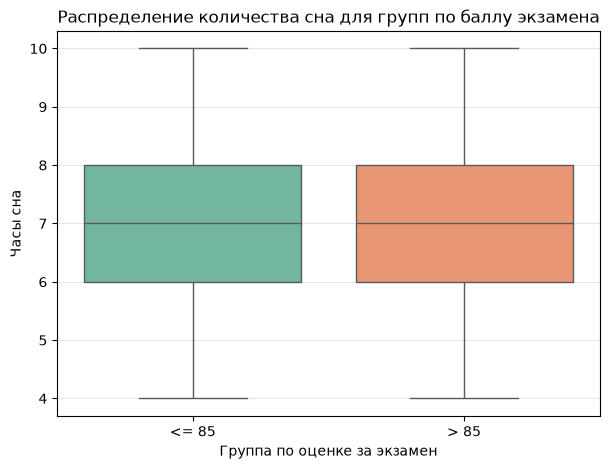

Медианное количество сна в обеих группах одинаково (7 часов).


In [35]:
df['Score_Group'] = df['Exam_Score'].apply(lambda x: '> 85' if x > 85 else '<= 85')

plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x='Score_Group', y='Sleep_Hours', hue='Score_Group', palette='Set2', legend=False)
plt.title('Распределение количества сна для групп по баллу экзамена')
plt.xlabel('Группа по оценке за экзамен')
plt.ylabel('Часы сна')
plt.grid(axis='y', alpha=0.3)
plt.show()

print("Медианное количество сна в обеих группах одинаково (7 часов).")

5. Правда ли, что количество посещаемых занятий с репетитором в месяц напрямую влияет на балл в конечном экзамене?

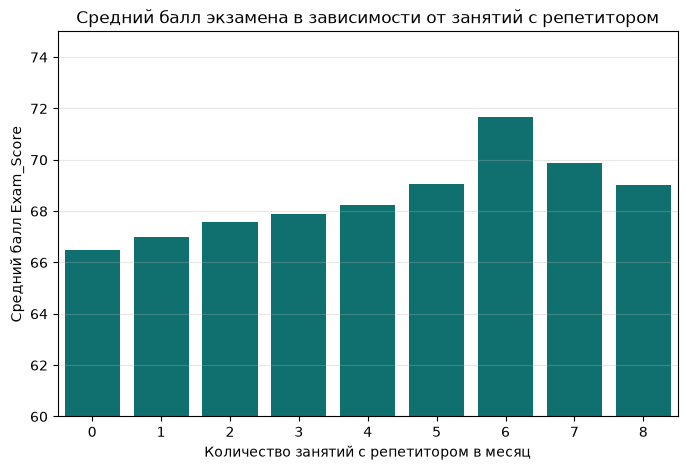

Вывод: Да, посещение занятий с репетитором напрямую влияет на результат — средний балл монотонно растет с количеством занятий.


In [36]:
plt.figure(figsize=(8, 5))
sns.barplot(data=df, x='Tutoring_Sessions', y='Exam_Score', errorbar=None, color='teal')
plt.title('Средний балл экзамена в зависимости от занятий с репетитором')
plt.xlabel('Количество занятий с репетитором в месяц')
plt.ylabel('Средний балл Exam_Score')
plt.ylim(60, 75)
plt.grid(axis='y', alpha=0.3)
plt.show()

print("Вывод: Да, посещение занятий с репетитором напрямую влияет на результат — средний балл монотонно растет с количеством занятий.")

6. Как физическая активность влияет на успеваемость?

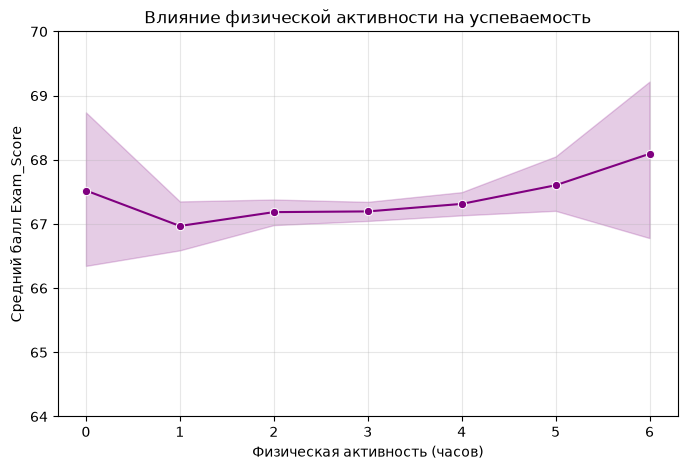

Вывод: Физическая активность практически не влияет на балл экзамена — колебания среднего балла незначительны.


In [38]:
plt.figure(figsize=(8, 5))
sns.lineplot(data=df, x='Physical_Activity', y='Exam_Score', marker='o', color='purple')
plt.title('Влияние физической активности на успеваемость')
plt.xlabel('Физическая активность (часов)')
plt.ylabel('Средний балл Exam_Score')
plt.ylim(64, 70)
plt.grid(alpha=0.3)
plt.show()

print("Вывод: Физическая активность практически не влияет на балл экзамена — колебания среднего балла незначительны.")

7. Постройте HeatMap где ось Х - процент посещаемость, Y - количество занятий с репетитором, а Z - балл за итоговый экзамен*

\* Задание на доп. балл

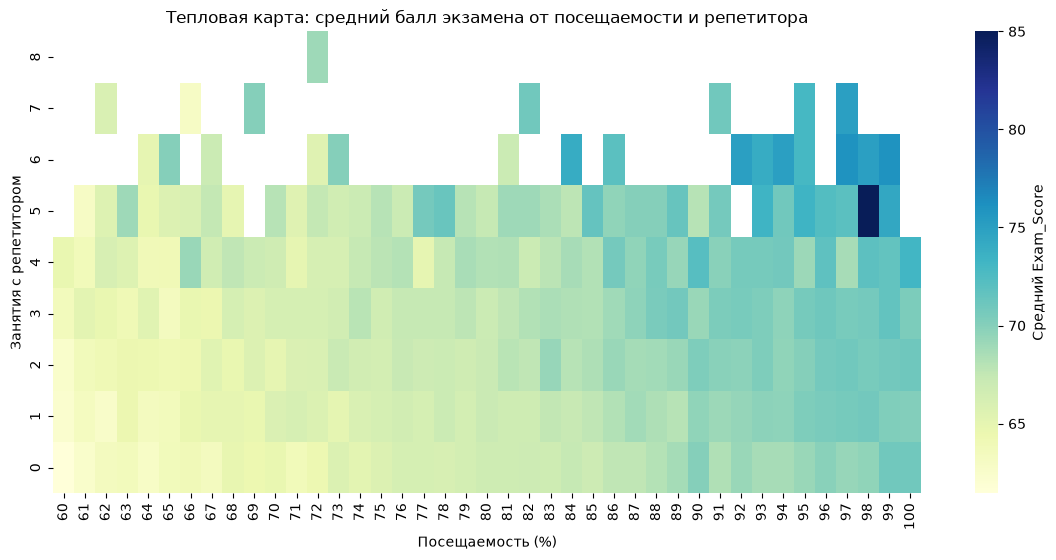

In [39]:
pivot_table = df.pivot_table(index='Tutoring_Sessions', columns='Attendance', values='Exam_Score', aggfunc='mean')

plt.figure(figsize=(14, 6))
sns.heatmap(pivot_table, cmap='YlGnBu', cbar_kws={'label': 'Средний Exam_Score'})
plt.title('Тепловая карта: средний балл экзамена от посещаемости и репетитора')
plt.xlabel('Посещаемость (%)')
plt.ylabel('Занятия с репетитором')
plt.gca().invert_yaxis()
plt.show()